# What Sets a Car's Price?

A dealership's records of 245 car sales: the model, the sale date, and the car's specifications (engine, size, weight, fuel economy). The task: clean the data, find what drives the price, and build a model that prices a car from its specifications.

**Data:** [cars.csv](cars.csv), a sample dataset of car sales. Columns with the owners' personal details (names, emails, addresses, bank accounts) are removed.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
cars = pd.read_csv("cars.csv", parse_dates=["saledate"])
print(cars.shape)
cars.head()

(245, 23)


,car_ID,CarName,saledate,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,carheight,curbweight,cylindernumber,enginesize,compressionratio,horsepower,peakrpm,citympg,highwaympg,Price
0,1,toyota corolla,2016-11-23,diesel,std,four,hatchback,fwd,front,95.7,...,52.8,2275,4.0,110,22.5,56.0,4500,38,47,7788.0
1,2,toyota carina,2020-08-11,gas,std,four,wagon,4wd,front,95.7,...,59.1,3110,4.0,92,9.0,62.0,4800,27,32,8778.0
2,3,toyota corolla,2018-06-26,gas,std,two,hatchback,rwd,front,98.4,...,52.0,2714,4.0,146,9.3,116.0,4800,24,30,11549.0
3,4,toyota corona,2018-07-24,gas,std,two,hatchback,rwd,front,102.9,...,52.0,3016,6.0,171,9.3,161.0,5200,19,24,15998.0
4,5,nissan otti,2022-02-10,gas,std,four,sedan,fwd,front,100.4,...,55.1,3060,6.0,181,9.0,152.0,5200,19,25,13499.0


## 1. Cleaning

In [3]:
missing = cars.isna().sum()
missing[missing > 0]

CarName           10
fueltype          10
carbody           10
enginelocation    10
carlength         10
cylindernumber    10
horsepower        10
dtype: int64

Seven columns have 10 missing values each, and the same 10 rows have no car name, fuel type, or body type. Without knowing what car it is, a row can't be priced, so those rows go. The other gaps are filled with the median.

The brand is the first word of the car name, and several are misspelled:

In [4]:
cars = cars.dropna(subset=["CarName", "fueltype", "carbody"]).copy()
fixes = {"maxda": "mazda", "toyouta": "toyota", "vw": "volkswagen", "vokswagen": "volkswagen",
         "porcshce": "porsche", "alfa-romero": "alfa-romeo"}
raw_brand = cars.CarName.str.split().str[0].str.lower()
print("fixed:", {k: v for k, v in fixes.items() if k in set(raw_brand)})
cars["brand"] = raw_brand.replace(fixes)

for col in ["carlength", "cylindernumber", "horsepower"]:
    cars[col] = cars[col].fillna(cars[col].median())
cars["enginelocation"] = cars.enginelocation.fillna(cars.enginelocation.mode()[0])
cars["doors"] = cars.doornumber.map({"two": 2, "four": 4})
print(f"{len(cars)} cars, {cars.brand.nunique()} brands, prices ${cars.Price.min():,.0f} to ${cars.Price.max():,.0f}")

fixed: {'maxda': 'mazda', 'toyouta': 'toyota', 'vw': 'volkswagen', 'vokswagen': 'volkswagen', 'porcshce': 'porsche', 'alfa-romero': 'alfa-romeo'}
235 cars, 22 brands, prices $5,118 to $45,400


## 2. What drives the price

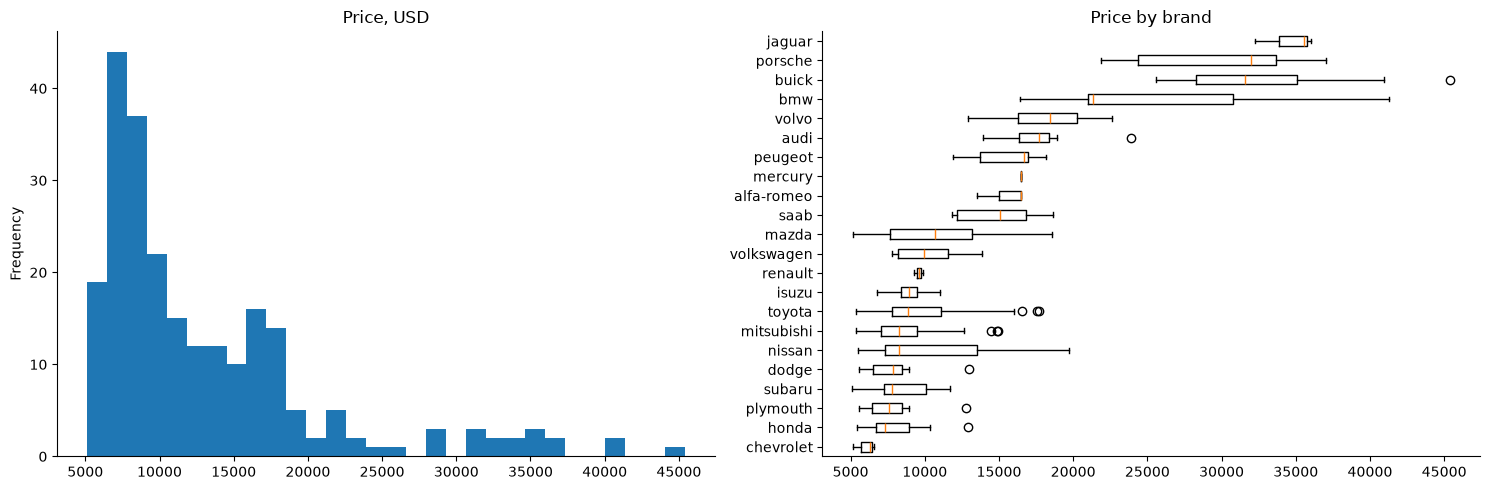

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cars.Price.plot.hist(bins=30, ax=axes[0], title="Price, USD")
order = cars.groupby("brand").Price.median().sort_values()
axes[1].boxplot([cars.loc[cars.brand == b, "Price"] for b in order.index], vert=False, tick_labels=order.index)
axes[1].set_title("Price by brand")
plt.tight_layout()
plt.show()

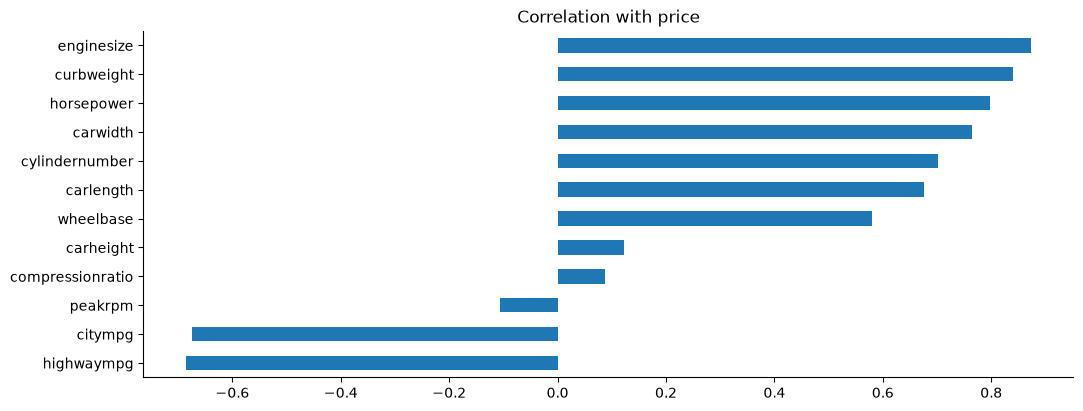

In [6]:
numeric = ["enginesize", "curbweight", "horsepower", "carwidth", "cylindernumber", "carlength", "wheelbase",
           "citympg", "highwaympg", "carheight", "compressionratio", "peakrpm"]
cars[numeric + ["Price"]].corr()["Price"].drop("Price").sort_values().plot.barh(title="Correlation with price")
plt.show()

Bigger, heavier, more powerful cars cost more, and fuel economy goes the other way: an efficient car is usually a small, cheap one. Several of these measure the same thing (engine size, horsepower, and cylinders; length, width, and weight), so the model uses a few combined features instead:

- **power to weight:** horsepower per kilogram of car,
- **combined fuel economy:** the average of city and highway miles per gallon,
- **luxury brand:** BMW, Jaguar, Porsche, Volvo, Audi, Buick, and Saab, whose median price stands well above the rest.

In [7]:
luxury = ["bmw", "jaguar", "porsche", "volvo", "audi", "buick", "saab"]
cars["power_to_weight"] = cars.horsepower / cars.curbweight
cars["mpg_combined"] = (cars.citympg + cars.highwaympg) / 2
cars["luxury_brand"] = cars.brand.isin(luxury).astype(int)
cars["sale_year"] = cars.saledate.dt.year
print(f"luxury cars: {cars.luxury_brand.mean():.0%} of sales, median ${cars[cars.luxury_brand == 1].Price.median():,.0f} "
      f"against ${cars[cars.luxury_brand == 0].Price.median():,.0f}")

luxury cars: 22% of sales, median $21,408 against $8,845


## 3. Models

With only 235 cars, a single train/test split gives noisy scores: a few expensive cars landing in the test set can change them a lot. So every model is scored by 5-fold cross-validation: the cars are split into 5 parts, each part is predicted by a model trained on the other 4, and the scores come from all 235 out-of-sample predictions.

In [8]:
categorical = ["fueltype", "aspiration", "carbody", "drivewheel", "enginelocation", "brand"]
numerical = ["carwidth", "power_to_weight", "mpg_combined", "luxury_brand", "enginesize", "curbweight", "sale_year"]
X, y = cars[categorical + numerical], cars.Price
encode = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), categorical), ("num", StandardScaler(), numerical)])

models = {
    "linear regression": make_pipeline(encode, LinearRegression()),
    "ridge": make_pipeline(encode, Ridge(alpha=3)),
    "random forest": make_pipeline(encode, RandomForestRegressor(n_estimators=400, min_samples_leaf=2, random_state=0)),
    "XGBoost": make_pipeline(encode, XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8,
                                                   colsample_bytree=0.8, random_state=0)),
}
folds = KFold(5, shuffle=True, random_state=0)
predictions = {name: cross_val_predict(m, X, y, cv=folds) for name, m in models.items()}
predictions["ridge + XGBoost, half each"] = (predictions["ridge"] + predictions["XGBoost"]) / 2

scores = pd.DataFrame({name: {"average error, USD": mean_absolute_error(y, p), "R²": r2_score(y, p),
                              "share underestimated": np.mean(p < y)} for name, p in predictions.items()}).T
scores.sort_values("average error, USD").round(3)

,"average error, USD",R²,share underestimated
XGBoost,1250.388,0.938,0.468
"ridge + XGBoost, half each",1287.086,0.939,0.481
random forest,1355.611,0.930,0.468
linear regression,1561.703,0.915,0.515
ridge,1589.903,0.912,0.485


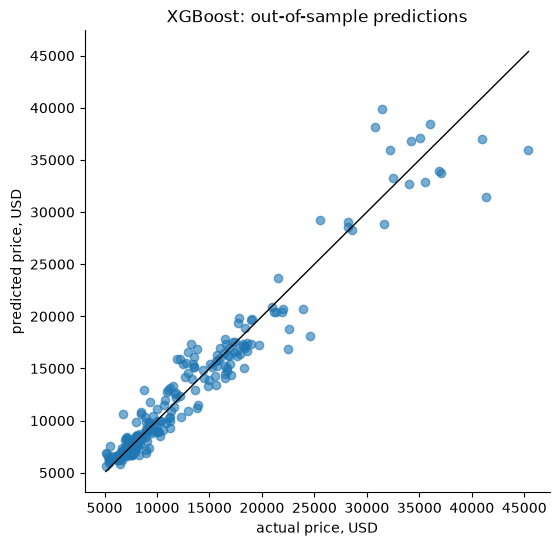

,CarName,Price,predicted,error
99,bmw x5,41315.0,31445.0,-9870.0
154,buick regal sport coupe (turbo),45400.0,35962.0,-9438.0
116,porsche cayenne,31400.0,39922.0,8522.0
9,bmw x4,30760.0,38168.0,7408.0
242,bmw z4,24565.0,18141.0,-6424.0


In [9]:
best = scores["average error, USD"].idxmin()
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y, predictions[best], alpha=0.6)
ax.plot([y.min(), y.max()], [y.min(), y.max()], color="black", lw=1)
ax.set_xlabel("actual price, USD")
ax.set_ylabel("predicted price, USD")
ax.set_title(f"{best}: out-of-sample predictions")
plt.show()

errors = cars.assign(predicted=predictions[best], error=predictions[best] - y)
errors.loc[errors.error.abs().nlargest(5).index, ["CarName", "Price", "predicted", "error"]].round(0)

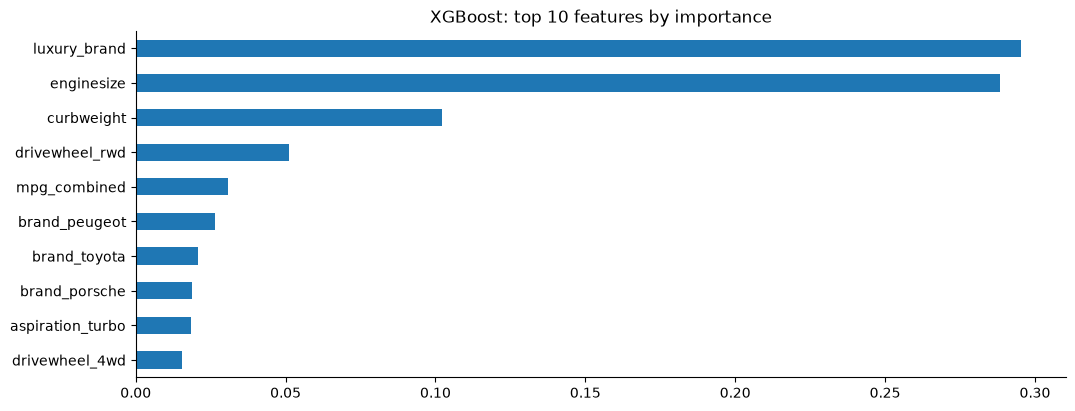

In [10]:
xgb_model = models["XGBoost"].fit(X, y)
names = xgb_model[0].get_feature_names_out()
importance = pd.Series(xgb_model[-1].feature_importances_, index=[re.sub(r"^(cat|num)__", "", n) for n in names])
importance.sort_values().tail(10).plot.barh(title="XGBoost: top 10 features by importance")
plt.show()

## Results

- Cleaning: 10 rows without a car name, fuel type, or body type were dropped, six misspelled brands were fixed (maxda, toyouta, vw, vokswagen, porcshce, alfa-romero), leaving 235 cars of 22 brands priced from \$5,118 to \$45,400.
- Price follows size and power: engine size, weight, horsepower, and width rise with it, fuel economy falls. Luxury brands are 22% of sales with a median price of \$21,408, against \$8,845 for the rest.
- In 5-fold cross-validation, XGBoost prices a car within \$1,250 on average (R² 0.94). A half-and-half blend with ridge regression is close (\$1,287), the random forest gives \$1,356, and linear models about \$1,560–1,590.
- XGBoost relies most on the luxury-brand flag and engine size, then weight and rear-wheel drive. Its biggest misses are luxury models whose price depends on more than their specifications, such as a BMW X5 priced about \$9,900 too low and a Porsche Cayenne about \$8,500 too high.

## Tools

Python, pandas, NumPy, scikit-learn, XGBoost, matplotlib